In [8]:
!pip install pandas numpy matplotlib seaborn scikit-learn joblib requests

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import requests
import zipfile
import io

# Download UCI Student Performance Dataset
url = "https://archive.ics.uci.edu/static/public/320/student+performance.zip"

response = requests.get(url)
response.raise_for_status()

# Extract dataset from nested zip
with zipfile.ZipFile(io.BytesIO(response.content)) as outer_zip:
    # Open the inner 'student.zip' archive from the outer archive
    with outer_zip.open("student.zip") as inner_zip_file:
        with zipfile.ZipFile(io.BytesIO(inner_zip_file.read())) as inner_zip:
            # Load student-mat.csv
            with inner_zip.open("student-mat.csv") as file:
                df = pd.read_csv(file, sep=";")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [10]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nDataset Columns:")
print(df.columns.tolist())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    o

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000



Duplicate Rows: 0

Dataset Columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


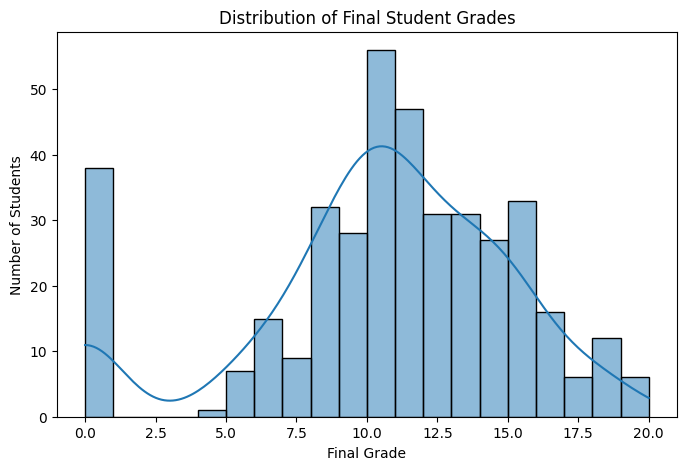

In [11]:
plt.figure(figsize=(8, 5))
sns.histplot(df["G3"], bins=20, kde=True)
plt.title("Distribution of Final Student Grades")
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")

plt.show()

In [12]:
def categorize_performance(grade):

    if grade < 10:
        return "Low"

    elif grade < 15:
        return "Average"

    else:
        return "High"


df["Performance"] = df["G3"].apply(categorize_performance)

print(df["Performance"].value_counts())

Performance
Average    192
Low        130
High        73
Name: count, dtype: int64


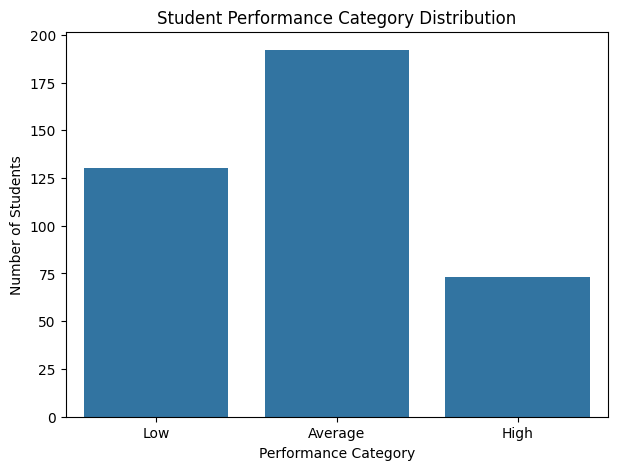

In [13]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Performance",
    order=["Low", "Average", "High"]
)

plt.title("Student Performance Category Distribution")
plt.xlabel("Performance Category")
plt.ylabel("Number of Students")

plt.show()

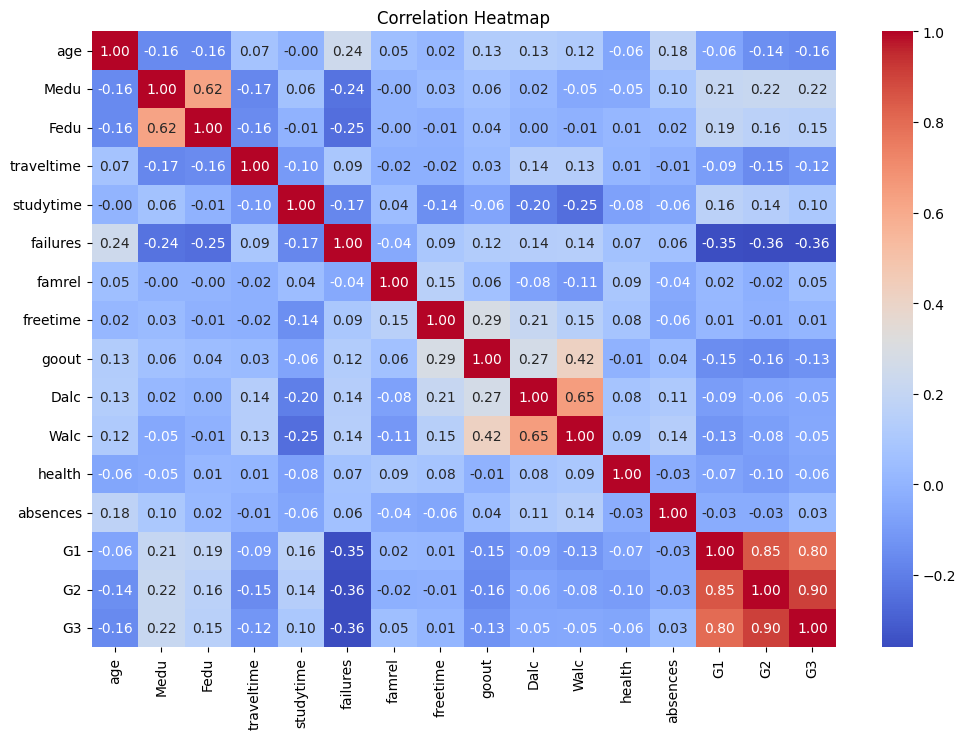

In [14]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [15]:
# Target variable
y = df["Performance"]

# Remove final and previous grades to prevent leakage
X = df.drop(columns=["G1", "G2", "G3", "Performance"])

print("Input Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.head())

# Check leakage
print("\nG1 in X:", "G1" in X.columns)
print("G2 in X:", "G2" in X.columns)
print("G3 in X:", "G3" in X.columns)

Input Features:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']

Target:
0        Low
1        Low
2    Average
3       High
4    Average
Name: Performance, dtype: object

G1 in X: False
G2 in X: False
G3 in X: False


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True))

Training Data: (316, 30)
Testing Data: (79, 30)

Training Target Distribution:
Performance
Average    0.487342
Low        0.329114
High       0.183544
Name: proportion, dtype: float64

Testing Target Distribution:
Performance
Average    0.481013
Low        0.329114
High       0.189873
Name: proportion, dtype: float64


In [17]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both transformations
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numerical Features:", len(numeric_features))
print("Categorical Features:", len(categorical_features))

print("Preprocessing pipeline created successfully!")

Numerical Features: 13
Categorical Features: 17
Preprocessing pipeline created successfully!


In [18]:
from sklearn.linear_model import LogisticRegression

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train using training data
model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [19]:
y_pred = model.predict(X_test)

print("Actual Values:")
print(y_test.head(10).values)

print("\nPredicted Values:")
print(y_pred[:10])

Actual Values:
['Low' 'Average' 'High' 'Low' 'Low' 'High' 'Average' 'Average' 'Low'
 'High']

Predicted Values:
['Low' 'High' 'Average' 'Average' 'Average' 'High' 'High' 'Low' 'Low'
 'High']


In [20]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

print("Baseline Accuracy:", baseline_accuracy)

Baseline Accuracy: 0.4810126582278481


In [21]:
from sklearn.metrics import (
    accuracy_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)

print("Logistic Regression Accuracy:", accuracy)

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    labels=["Low", "Average", "High"],
    zero_division=0
))

print("Baseline Accuracy:", baseline_accuracy)
print("Model Accuracy:", accuracy)

Logistic Regression Accuracy: 0.379746835443038

Classification Report:

              precision    recall  f1-score   support

         Low       0.47      0.58      0.52        26
     Average       0.33      0.24      0.28        38
        High       0.30      0.40      0.34        15

    accuracy                           0.38        79
   macro avg       0.37      0.40      0.38        79
weighted avg       0.37      0.38      0.37        79

Baseline Accuracy: 0.4810126582278481
Model Accuracy: 0.379746835443038


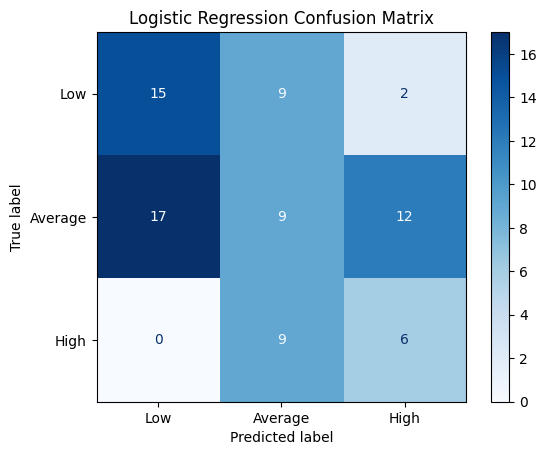

In [22]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

labels = ["Low", "Average", "High"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(cmap="Blues")

plt.title("Logistic Regression Confusion Matrix")

plt.show()

In [23]:
results = X_test.copy()

results["Actual"] = y_test
results["Predicted"] = y_pred

errors = results[
    results["Actual"] != results["Predicted"]
]

print("Total Incorrect Predictions:", len(errors))

print("\nFirst Two Incorrect Predictions:")

display(errors.head(2))

Total Incorrect Predictions: 49

First Two Incorrect Predictions:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,Actual,Predicted
375,MS,F,18,R,GT3,T,1,1,other,other,...,no,4,3,2,1,2,4,2,Average,High
158,GP,M,16,R,GT3,T,2,2,at_home,other,...,no,4,2,2,1,2,3,2,High,Average


In [24]:
# Select one student from test data
sample_student = X_test.iloc[[0]]

# Actual performance
actual_performance = y_test.iloc[0]

# Predict performance
predicted_performance = model.predict(sample_student)[0]

print("Student Information:")
display(sample_student)

print("Actual Performance:", actual_performance)
print("Predicted Performance:", predicted_performance)

Student Information:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences
383,MS,M,19,R,GT3,T,1,1,other,services,...,yes,no,no,4,3,2,1,3,5,0


Actual Performance: Low
Predicted Performance: Low


In [25]:
import joblib

joblib.dump(model, "edupredict_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [26]:
import joblib

joblib.dump(model, "edupredict_model.pkl")

['edupredict_model.pkl']

In [28]:
from google.colab import files

files.download("edupredict_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>